# AI-гид Москвы: EDA корпуса POI и текстовых фрагментов

Задача — собрать датасет достопримечательностей Москвы с нуля и в дальнейшем классифицировать фрагменты описаний достопримечательностей по темам, чтобы затем подбирать факты под интересы пользователя

Источники: исходный каталог команды, Wikidata и русская Википедия

### О датасете

В начале пайплайна мы используем файл `poi_candidates_229.csv`. Это **исходный сырой реестр кандидатов** — список из 229 потенциальных достопримечательностей Москвы и ближайших пригородов, которые могут стать точками для экскурсии.

Список собирался **вручную** на основе популярных туристических маршрутов, путеводителей и реестров культурного наследия. Объекты сгруппированы по логическим кластерам `area_group`, чтобы в будущем облегчить построение маршрутов (например, «Кремль и Красная площадь», «ВДНХ», «Коломенское»).

На вход мы подаем **только текстовые названия**. Колонки с метаданными пусты, потому что они заполняются прямо во время выполнения этого ноутбука:
*   **`article_title`** точное название статьи в русской Википедии
*   **`qid`** уникальный идентификатор объекта в Wikidata нужен для получения координат и связей.
*   **`latitude` / `longitude`** географические координаты
*   **`sitelinks`** количество языковых версий статьи
*   **`match_status`** статус сопоставления `candidate` меняется на `wiki_matched` или `not_matched`

При первом запуске в новой среде нужно загрузить `poi_candidates_229.csv` в файле 229 записей.
Повторные запуски используют этот CSV и завершённый снимок текстов из папки результатов.
Для обновления текстов установите `REFRESH_TEXT = True` в блоке 4


## Подготовка среды

- Устанавливаем библиотеки для загрузки данных, обработки текста, графиков и baseline


In [1]:
!pip -q install pandas numpy matplotlib seaborn requests scikit-learn tqdm beautifulsoup4


### Настройки запуска

- Импортируем библиотеки, задаём seed и оформление графиков
- Создаём папки для таблиц и изображений


In [2]:
import re, json, time, random, warnings
from pathlib import Path
from urllib.parse import quote
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm
from sklearn.model_selection import GroupShuffleSplit
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.multiclass import OneVsRestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, f1_score, hamming_loss
plt.rcParams.update({'font.family': 'DejaVu Sans', 'figure.dpi': 110})
FIG_DIR = Path('/content/moscow_ai_guide_output/figures')
FIG_DIR.mkdir(parents=True, exist_ok=True)
SEED = 42
random.seed(SEED); np.random.seed(SEED)
OUT_DIR = Path('/content/moscow_ai_guide_output')
OUT_DIR.mkdir(exist_ok=True)


## 1. Загрузка каталога кандидатов

- Читаем CSV и проверяем обязательные поля и уникальность ID
- Считаем записи по группам мест


In [3]:
from google.colab import files
csv_path = Path('/content/poi_candidates_229.csv')
if not csv_path.exists():
    uploaded = files.upload()  # только при первом запуске в новой среде
    csv_path = Path(next(iter(uploaded)))
pois_seed = pd.read_csv(csv_path)
required = {'poi_id', 'wiki_title_seed', 'area_group'}
assert required.issubset(pois_seed.columns), 'В CSV не хватает обязательных колонок'
assert pois_seed.poi_id.is_unique, 'В исходном CSV повторяются poi_id'
print('Кандидатов:', len(pois_seed))
display(pois_seed.groupby('area_group').size().sort_values(ascending=False).to_frame('count'))


Saving poi_candidates_229.csv to poi_candidates_229.csv
Кандидатов: 229


,count
area_group,
Кремль и Красная площадь,48
Запад и юго-запад Москвы,26
Музеи и культурные площадки,25
"ВДНХ, Останкино и северо-восток",25
"Коломенское, Царицыно, Кусково и восток",24
Замоскворечье и Якиманка,24
"Арбат, Пречистенка и Хамовники",22
"Метро, вокзалы и мосты",20
Храмы и религиозные объекты,15


**Промежуточный вывод**

- На «Кремль и Красную площадь» приходится 48 из 229 записей, около 21%. Группы представлены неравномерно
- Состав каталога влияет на частоты тем, поэтому баланс меток нельзя считать распределением интересов туристов


## 2. Сопоставление с русской Википедией и Wikidata

- Находим точные статьи, уточняем неоднозначные названия и получаем QID
- Отбрасываем страницы значений, неразрешённые названия оставляем для проверки


In [4]:
S = requests.Session()
S.headers.update({
    'User-Agent': f'AIStorytellingGuide/0.1 (https://github.com/uandr/ai-storytelling-guide) requests/{requests.__version__}',
    'Accept': 'application/json'
})

def wiki_json(params):
    """Запрос к API: проверяем HTTP и ограничиваем повторы при перегрузке."""
    for attempt in range(3):
        r = S.get("https://ru.wikipedia.org/w/api.php",
                  params={**params, "maxlag": 5}, timeout=30)
        if r.status_code in (429, 503) and attempt < 2:
            retry_after = r.headers.get('Retry-After')
            try:
                delay = float(retry_after) if retry_after else 5 * (2 ** attempt)
            except ValueError:
                # Retry-After может содержать HTTP-дату вместо числа секунд.
                from datetime import datetime, timezone
                from email.utils import parsedate_to_datetime
                delay = (parsedate_to_datetime(retry_after) - datetime.now(timezone.utc)).total_seconds()
            if delay > 60:
                raise RuntimeError(f'Wikipedia API: HTTP {r.status_code}, Retry-After={retry_after}. Повторите ячейку позже.')
            time.sleep(max(0, delay))
            continue
        # Ошибку API нельзя выдавать за отсутствие статьи.
        r.raise_for_status()
        try:
            data = r.json()
        except ValueError as exc:
            raise RuntimeError(f'Wikipedia API вернул не JSON: HTTP {r.status_code}, Content-Type={r.headers.get("Content-Type")}') from exc
        if 'error' in data:
            raise RuntimeError(f'Wikipedia API: {data["error"]}')
        return data


# Явные уточнения неоднозначных названий, без выбора первого результата поиска
TITLE_OVERRIDES = {'Казанский собор на Красной площади': 'Казанский собор (Москва)', 'Успенский собор': 'Успенский собор (Московский Кремль)', 'Архангельский собор': 'Архангельский собор (Московский Кремль)', 'Благовещенский собор': 'Благовещенский собор (Московский Кремль)', 'Александровский сад': 'Александровский сад (Москва)', 'Манежная площадь': 'Манежная площадь (Москва)', 'Никольская улица': 'Никольская улица (Москва)', 'Ильинка': 'Ильинка (улица)', 'Парящий мост': 'Парящий мост (Москва)', 'Знаменский монастырь': 'Знаменский монастырь (Москва)', 'Площадь Революции': 'Площадь Революции (Москва)', 'Театральная площадь': 'Театральная площадь (Москва)', 'Манеж': 'Манеж (Москва)', 'Памятник Петру I': 'Памятник Петру I (Москва)', 'Крымский мост': 'Крымский мост (Москва)', 'Парк Горького': 'Парк Горького (Москва)', 'Церковь Климента папы Римского': 'Храм Климента Папы Римского (Москва)', 'ГЭС-2': 'ГЭС-2 (Москва)', 'Дом культуры ГЭС-2': 'ГЭС-2 (Москва)', 'Ордынка': 'Большая Ордынка', 'Министерство иностранных дел России': 'Здание Министерства иностранных дел России', 'Памятник Гоголю': 'Памятник Гоголю (Никитский бульвар)', 'Лужники': 'Лужники (олимпийский комплекс)', 'Парк Победы': 'Парк Победы (Москва)', 'Триумфальная арка': 'Триумфальные ворота (Москва)', 'Парк 50-летия Октября': 'Парк 50-летия Октября (Москва)', 'Музей космонавтики': 'Мемориальный музей космонавтики', 'Царицыно': 'Царицыно (дворцово-парковый ансамбль)', 'Хлебный дом': 'Хлебный дом (Царицыно)', 'Преображенское': 'Преображенское (район Москвы)', 'Собор Покрова в Измайлове': 'Храм Покрова Богородицы в Измайлове', 'Екатерининский парк': 'Екатерининский парк (Москва)', 'Музей Булгакова': 'Музей Михаила Булгакова', 'Музей-квартира Достоевского': 'Музей-квартира Ф. М. Достоевского (Москва)', 'Музей Сергея Есенина': 'Московский государственный музей С. А. Есенина', 'Музей Владимира Маяковского': 'Государственный музей В. В. Маяковского', 'Центр современного искусства Винзавод': 'Винзавод', 'Галерея Гараж': 'Музей современного искусства «Гараж»', 'Библиотека имени Ленина': 'Российская государственная библиотека', 'Сретенский монастырь': 'Сретенский монастырь (Москва)', 'Храм Григория Неокесарийского': 'Храм Григория Неокесарийского (Москва)', 'Собор Непорочного Зачатия Пресвятой Девы Марии': 'Собор Непорочного Зачатия Пресвятой Девы Марии (Москва)', 'Станция метро Маяковская': 'Маяковская (станция метро, Москва)', 'Станция метро Комсомольская': 'Комсомольская (станция метро, Кольцевая линия)', 'Станция метро Киевская': 'Киевская (станция метро, Кольцевая линия)', 'Станция метро Новослободская': 'Новослободская', 'Станция метро Площадь Революции': 'Площадь Революции (станция метро, Москва)', 'Станция метро Кропоткинская': 'Кропоткинская', 'Станция метро Белорусская': 'Белорусская (станция метро, Кольцевая линия)', 'Станция метро Славянский бульвар': 'Славянский бульвар (станция метро)', 'Павильон Золотой колос': 'Золотой колос (фонтан)', 'Музей-квартира Чехова': 'Дом-музей А. П. Чехова (Москва)', 'Исторический музей Москвы': 'Государственный исторический музей', 'Храм Максима Блаженного': 'Церковь Максима Блаженного', 'Парк искусств Музеон': 'Музеон (парк)', 'Храм Николы в Толмачах': 'Храм Святителя Николая в Толмачах', 'Музей-квартира Александра Пушкина на Арбате': 'Мемориальная квартира Пушкина на Арбате', 'Усадьба Льва Толстого в Хамовниках': 'Музей-усадьба Льва Толстого в Хамовниках', 'Смотровая площадка Воробьёвых гор': 'Воробьёвы горы', 'Большая спортивная арена Лужники': 'Лужники (стадион)', 'Музей-заповедник Царицыно': 'Царицыно (дворцово-парковый ансамбль)', 'Парк Крылатские холмы': 'Крылатские холмы', 'Гребной канал в Крылатском': 'Москва (гребной канал)', 'Фонтан Дружба народов': 'Дружба народов (фонтан)', 'Фонтан Каменный цветок': 'Каменный цветок (фонтан)', 'Павильон Космос': 'Павильон № 34 «Космос» на ВДНХ', 'Усадьба Останкино': 'Останкино (усадьба)', 'Ботанический сад РАН': 'Главный ботанический сад имени Н. В. Цицина РАН', 'Главный ботанический сад имени Цицина': 'Главный ботанический сад имени Н. В. Цицина РАН', 'Парк Останкино': 'Останкино (парк)', 'Монумент Покорителям космоса': 'Покорителям космоса', 'Парк Яуза': 'Яуза (парк)', 'Сад будущего': 'Сад будущего (парк)', 'Павильон Макет Москвы': 'Павильон № 70 «Москва» на ВДНХ', 'Павильон Беларусь': 'Павильон № 18 «Республика Беларусь» на ВДНХ', 'Павильон Армения': 'Павильон № 68 «Армения» на ВДНХ', 'Павильон Украина': 'Павильон № 58 «Земледелие» на ВДНХ', 'Павильон Земледелие': 'Павильон № 58 «Земледелие» на ВДНХ', 'Большой дворец в Царицыно': 'Большой Царицынский дворец', 'Усадьба Измайлово': 'Измайлово (усадьба)', 'Парк Измайлово': 'Измайлово (природно-исторический парк)', 'Парк Аршиновский': 'Аршиновский парк', 'Государственный музей изобразительных искусств имени Пушкина': 'Государственный музей изобразительных искусств имени А. С. Пушкина', 'Музей-панорама Бородинская битва': 'Бородинская панорама', 'Музей-заповедник Архангельское': 'Архангельское (музей-усадьба)', 'Храм Живоначальной Троицы в Останкине': 'Храм Троицы Живоначальной в Останкине'}

def resolve_exact_batch(titles):
    data = wiki_json({'action': 'query', 'format': 'json', 'redirects': 1,
                     'prop': 'pageprops|coordinates', 'titles': '|'.join(titles),
                     'colimit': 'max', 'coprimary': 'primary'})
    query = data.get('query', {})
    aliases = {p['from']: p['to'] for key in ('normalized', 'redirects') for p in query.get(key, [])}
    pages = {p['title']: p for p in query.get('pages', {}).values()}
    result = {}
    for title in titles:
        canonical = title
        for _ in range(10):
            if canonical not in aliases:
                break
            canonical = aliases[canonical]
        page = pages.get(canonical, {})
        props = page.get('pageprops', {})
        disambig = 'disambiguation' in props
        valid = 'missing' not in page and props.get('wikibase_item') and not disambig
        coords = page.get('coordinates', [{}])[0]
        result[title] = {
            'article_title': page.get('title') if valid else np.nan,
            'qid': props.get('wikibase_item') if valid else np.nan,
            'wiki_url': 'https://ru.wikipedia.org/wiki/' + quote(page['title'].replace(' ', '_')) if valid else np.nan,
            'wp_latitude': coords.get('lat', np.nan), 'wp_longitude': coords.get('lon', np.nan),
            'is_disambiguation': disambig,
            'review_reason': 'страница значений' if disambig else ('' if valid else 'нет точной статьи или QID')
        }
    return result

requested = pois_seed.wiki_title_seed.map(lambda t: TITLE_OVERRIDES.get(t, t))
lookup = {}
unique_titles = requested.drop_duplicates().tolist()
for i in tqdm(range(0, len(unique_titles), 10)):
    lookup.update(resolve_exact_batch(unique_titles[i:i+10]))
    time.sleep(1)
seed_cols = ['poi_id', 'wiki_title_seed', 'area_group']
pois = pd.concat([pois_seed[seed_cols].reset_index(drop=True),
                  pd.DataFrame([lookup[t] for t in requested])], axis=1)
pois['requested_title'] = requested.to_numpy()
pois['match_status'] = np.where(pois.qid.isna(), 'review_required',
    np.where(pois.wiki_title_seed.isin(TITLE_OVERRIDES), 'explicit_title', 'exact_title'))
pois.to_csv(OUT_DIR/'poi_matches.csv', index=False, encoding='utf-8-sig')
print('Сопоставлено:', pois.qid.notna().sum(), 'из', len(pois))
print('Уточнений названия:', pois.wiki_title_seed.isin(TITLE_OVERRIDES).sum())
display(pois[pois.qid.isna()][['poi_id', 'wiki_title_seed', 'requested_title', 'review_reason']])


  0%|          | 0/22 [00:00<?, ?it/s]

Сопоставлено: 226 из 229
Уточнений названия: 87


,poi_id,wiki_title_seed,requested_title,review_reason
34,POI_035,Парящий мост,Парящий мост (Москва),нет точной статьи или QID
107,POI_108,Сетуньский стан,Сетуньский стан,нет точной статьи или QID
193,POI_194,Музей иллюзий Москвы,Музей иллюзий Москвы,нет точной статьи или QID


**Промежуточный вывод**

- Для 226 из 229 записей нашлись статьи, для 87 использованы уточнённые названия. Одного исходного названия недостаточно для надёжного сопоставления
- Три неразрешённых случая отложены. Подстановка первого результата поиска добавляла бы в корпус тексты о других объектах


### Обогащение данными Wikidata

- Получаем координаты P625 и число ссылок на проекты Wikimedia
- Дополняем отсутствующие координаты данными статьи Википедии и сохраняем источник каждой точки


In [5]:
matched_qids = pois.qid.dropna().unique().tolist()
wd_rows = []
for i in tqdm(range(0, len(matched_qids), 50)):
    params = {'action': 'wbgetentities', 'ids': '|'.join(matched_qids[i:i+50]),
              'props': 'claims|sitelinks', 'format': 'json'}
    for attempt in range(3):
        r = S.get('https://www.wikidata.org/w/api.php', params=params, timeout=40)
        if r.status_code in (429, 503) and attempt < 2:
            time.sleep(5 * (attempt + 1))
            continue
        r.raise_for_status()
        data = r.json()
        if 'error' in data:
            raise RuntimeError(f'Wikidata API: {data["error"]}')
        break
    for qid, entity in data.get('entities', {}).items():
        claims = [c for c in entity.get('claims', {}).get('P625', []) if c.get('rank') != 'deprecated']
        claims.sort(key=lambda c: c.get('rank') != 'preferred')
        value = next((c['mainsnak']['datavalue']['value'] for c in claims
                      if 'datavalue' in c.get('mainsnak', {})), {})
        wd_rows.append({'qid': qid, 'wd_latitude': value.get('latitude', np.nan),
                        'wd_longitude': value.get('longitude', np.nan),
                        'sitelinks': len(entity.get('sitelinks', {}))})
    time.sleep(0.5)
wd = pd.DataFrame(wd_rows)
pois = pois.drop(columns=['wd_latitude', 'wd_longitude', 'latitude', 'longitude', 'sitelinks',
                          'coordinate_source'], errors='ignore').merge(wd, on='qid', how='left')
pois['latitude'] = pois.wd_latitude.combine_first(pois.wp_latitude)
pois['longitude'] = pois.wd_longitude.combine_first(pois.wp_longitude)
pois['coordinate_source'] = np.select([pois.wd_latitude.notna(), pois.wp_latitude.notna()],
                                       ['Wikidata P625', 'Wikipedia coordinates'], default='missing')
pois['inside_bbox'] = pois.latitude.between(55.10, 56.10) & pois.longitude.between(36.70, 38.20)
pois.to_csv(OUT_DIR/'pois_enriched.csv', index=False, encoding='utf-8-sig')
print('С координатами:', pois.latitude.notna().sum(), 'из', len(pois))
display(pois[['qid', 'latitude', 'longitude', 'sitelinks']].describe())
display(pois[['article_title', 'coordinate_source']].groupby('coordinate_source').count())


  0%|          | 0/5 [00:00<?, ?it/s]

С координатами: 225 из 229


,latitude,longitude,sitelinks
count,225.000000,225.000000,226.000000
mean,55.752794,37.610554,18.362832
std,0.041787,0.065172,18.227238
min,55.615468,37.284167,1.000000
25%,55.735554,37.596956,5.000000
50%,55.751732,37.616667,12.500000
75%,55.767032,37.629486,26.000000
max,55.844518,37.807500,102.000000


,article_title
coordinate_source,
Wikidata P625,222
Wikipedia coordinates,3
missing,1


**Промежуточный вывод**

- Координаты получены для 225 записей: 222 из Wikidata и ещё три из статей Википедии
- Среди сопоставленных объектов один остался без координат. Его текст можно использовать, но для включения объекта в маршрут точку нужно проверить отдельно


## 3. Географическая проверка

- Ищем координаты вне широкой рамки Москвы и ближайших туристических территорий
- Отделяем спорные записи, убираем повторы QID и показываем объекты корпуса на карте


Вне контрольной рамки: 0
Без координат: 4
Отложено до проверки: 3
Уникальных объектов для корпуса: 206


,poi_id,wiki_title_seed,article_title,review_reason,latitude,longitude
34,POI_035,Парящий мост,NaN,нет точной статьи или QID,NaN,NaN
107,POI_108,Сетуньский стан,NaN,нет точной статьи или QID,NaN,NaN
193,POI_194,Музей иллюзий Москвы,NaN,нет точной статьи или QID,NaN,NaN


,missing_count,missing_pct
poi_id,0,0.0
wiki_title_seed,0,0.0
area_group,0,0.0
article_title,3,1.3
qid,3,1.3
wiki_url,3,1.3
wp_latitude,10,4.4
wp_longitude,10,4.4
is_disambiguation,0,0.0
review_reason,0,0.0


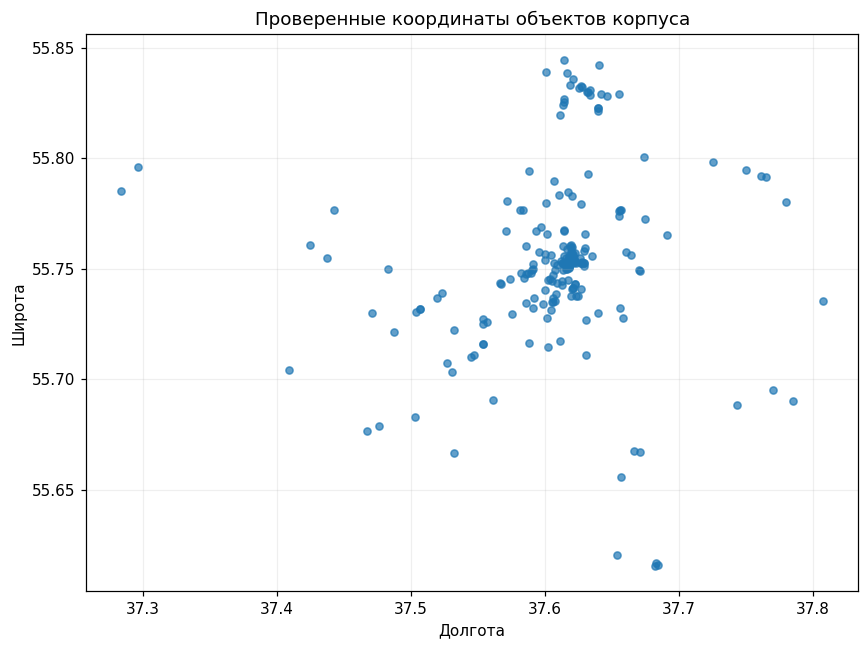

In [6]:
has_geo = pois[['latitude', 'longitude']].notna().all(axis=1)
geo_outliers = pois[has_geo & ~pois.inside_bbox].copy()
review_pois = pois[pois.qid.isna() | (has_geo & ~pois.inside_bbox)].copy()
review_pois.to_csv(OUT_DIR/'poi_review_required.csv', index=False, encoding='utf-8-sig')
geo_outliers.to_csv(OUT_DIR/'geographic_outliers_review.csv', index=False, encoding='utf-8-sig')
eligible_pois = pois[pois.qid.notna() & ~(has_geo & ~pois.inside_bbox)].copy()
unique_pois = eligible_pois.drop_duplicates('qid').reset_index(drop=True)
unique_pois.to_csv(OUT_DIR/'pois_corpus.csv', index=False, encoding='utf-8-sig')
print('Вне контрольной рамки:', len(geo_outliers))
print('Без координат:', (~has_geo).sum())
print('Отложено до проверки:', len(review_pois))
print('Уникальных объектов для корпуса:', len(unique_pois))
display(review_pois[['poi_id', 'wiki_title_seed', 'article_title', 'review_reason', 'latitude', 'longitude']])
display(pois.isna().sum().to_frame('missing_count').assign(missing_pct=lambda x: (100*x.missing_count/len(pois)).round(1)))
valid_geo = eligible_pois.dropna(subset=['latitude', 'longitude']).drop_duplicates('qid')
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(valid_geo.longitude, valid_geo.latitude, s=22, alpha=0.7)
ax.set(xlabel='Долгота', ylabel='Широта', title='Проверенные координаты объектов корпуса')
ax.grid(alpha=0.2)
plt.tight_layout(); fig.savefig(FIG_DIR/'01_geography.png'); plt.show()


**Промежуточный вывод**

- Проверка выявила четыре записи с координатами чужих городов. После исправления статей выбросов нет, в корпус допущены 206 уникальных объектов
- Географии недостаточно: «Музей иллюзий» раньше сопоставлялся с Кусковом, которое тоже находится в Москве. Нужно проверять и соответствие названия содержанию статьи


## 4. Загрузка статей и извлечение разделов

- Загружаем статьи или используем завершённый снимок текстов
- Убираем библиографию, ссылки, примечания и технические блоки
- Сохраняем содержательные разделы вместе с объектом, QID и URL источника


In [7]:
from bs4 import BeautifulSoup

def get_sections(title):
    html = wiki_json({'action': 'parse', 'page': title, 'prop': 'text',
                      'format': 'json', 'redirects': 1})['parse']['text']['*']
    soup = BeautifulSoup(html, 'html.parser')
    content = soup.find('div', class_='mw-parser-output')
    if content is None:
        return []
    for tag in content.select('script, style, table, sup, .mw-editsection, .navbox, .hatnote, .reflist, .mw-references-wrap'):
        tag.decompose()
    excluded = {'примечания', 'ссылки', 'литература', 'библиография', 'источники', 'см. также'}
    sections, current_text = [], []
    current_title, skip, skip_level = 'Введение', False, 0
    def flush():
        text = re.sub(r'\s+', ' ', ' '.join(current_text)).strip()
        if not skip and len(text) > 80:
            sections.append({'section_title': current_title, 'section_text': text})
    for block in content.find_all(['h2', 'h3', 'h4', 'p', 'ul', 'ol']):
        if block.find_parent(['p', 'ul', 'ol']) is not None:
            continue  # вложенный абзац уже входит в текст списка
        if block.name.startswith('h'):
            flush()
            current_text = []
            level = int(block.name[1])
            current_title = block.get_text(' ', strip=True)
            if current_title.lower().strip() in excluded:
                skip, skip_level = True, level
            elif not skip or level <= skip_level:
                skip = False
        elif not skip:
            text = block.get_text(' ', strip=True)
            if text:
                current_text.append(text)
    flush()
    return sections

REFRESH_TEXT = False  # True — скачать заново, False — использовать завершённый снимок
mapping = dict(zip(unique_pois.qid, unique_pois.article_title))
summary_path = OUT_DIR/'run_summary.json'
previous_run = json.loads(summary_path.read_text()) if summary_path.exists() else {}
use_snapshot = (not REFRESH_TEXT and (OUT_DIR/'wiki_sections.csv').exists()
    and previous_run.get('text_parser_version') == 2
    and previous_run.get('article_mapping') == mapping
    and previous_run.get('articles_downloaded') == len(unique_pois))
if use_snapshot:
    sections = pd.read_csv(OUT_DIR/'wiki_sections.csv', dtype={'qid': str})
    assert not sections.empty and set(sections.qid) == set(mapping), 'Снимок корпуса неполон'
    successful_articles = sections.qid.nunique()
    failed_articles = []
    print('Используем сохранённый снимок текстов')
else:
    section_rows, failed_articles = [], []
    successful_articles = 0
    print('Скачиваем статей:', len(unique_pois))
    for row in tqdm(unique_pois.itertuples(index=False), total=len(unique_pois)):
        try:
            article_sections = get_sections(row.article_title)
            if not article_sections:
                raise ValueError('Нет содержательных разделов')
            for section_no, sec in enumerate(article_sections):
                section_rows.append({'poi_id': row.poi_id, 'qid': row.qid,
                    'poi_title': row.article_title, 'source': 'Wikipedia RU',
                    'source_url': row.wiki_url, 'section_id': f'{row.qid}_s{section_no:03d}', **sec})
            successful_articles += 1
        except Exception as exc:
            failed_articles.append({'article_title': row.article_title, 'error': str(exc)[:200]})
            print('Не загружено:', row.article_title, str(exc)[:100])
        time.sleep(0.5)
    sections = pd.DataFrame(section_rows)
    if sections.empty:
        raise RuntimeError('Корпус пуст — проверьте загрузку статей')
sections.to_csv(OUT_DIR/'wiki_sections.csv', index=False, encoding='utf-8-sig')
pd.DataFrame(failed_articles, columns=['article_title', 'error']).to_csv(OUT_DIR/'download_failures.csv', index=False)
print('Загружено статей:', successful_articles, 'из', len(unique_pois))
print('Разделов:', len(sections))
display(sections.head())


Скачиваем статей: 206


  0%|          | 0/206 [00:00<?, ?it/s]

Загружено статей: 206 из 206
Разделов: 1978


,poi_id,qid,poi_title,source,source_url,section_id,section_title,section_text
0,POI_001,Q133274,Московский Кремль,Wikipedia RU,https://ru.wikipedia.org/wiki/%D0%9C%D0%BE%D1%...,Q133274_s000,Введение,Моско́вский Кремль — крепость в центре Москвы ...
1,POI_001,Q133274,Московский Кремль,Wikipedia RU,https://ru.wikipedia.org/wiki/%D0%9C%D0%BE%D1%...,Q133274_s001,Древнейшие поселения,Первые поселения на территории Московского Кре...
2,POI_001,Q133274,Московский Кремль,Wikipedia RU,https://ru.wikipedia.org/wiki/%D0%9C%D0%BE%D1%...,Q133274_s002,Поселение вятичей,С началом в X веке славянской колонизации басс...
3,POI_001,Q133274,Московский Кремль,Wikipedia RU,https://ru.wikipedia.org/wiki/%D0%9C%D0%BE%D1%...,Q133274_s003,Первая крепость,Датируемый XVII веком список Тверской летописи...
4,POI_001,Q133274,Московский Кремль,Wikipedia RU,https://ru.wikipedia.org/wiki/%D0%9C%D0%BE%D1%...,Q133274_s004,Княжеская резиденция,С 1264 года Кремль являлся резиденцией московс...


**Промежуточный вывод**

- Загрузились все 206 статей, получились 1978 содержательных разделов. В этом прогоне потерь из-за недоступных статей нет
- Раздел «Литература» со списком источников не означает литературную тему рассказа. Исключение библиографии устраняет такой источник ложных меток


## 5. Разбиение разделов на фрагменты

- Нарезаем текст окнами до 180 слов с перекрытием 35 слов, фрагменты короче 35 слов отбрасываем
- Присваиваем уникальные ID, удаляем точные дубли и тексты с низкой долей кириллицы


In [8]:
if sections.empty:
    raise ValueError('Нет разделов для нарезки — сначала выполните загрузку статей')

def make_chunks(text, max_words=180, overlap=35):
    words = text.split()
    chunks = []
    for start in range(0, len(words), max_words-overlap):
        part = words[start:start+max_words]
        if len(part) >= 35:
            chunks.append(' '.join(part))
        if start+max_words >= len(words):
            break
    return chunks

fragment_rows = []
for section_no, r in sections.reset_index(drop=True).iterrows():
    for chunk_no, chunk in enumerate(make_chunks(r.section_text)):
        fragment_rows.append({'fragment_id': f'{r.poi_id}_s{section_no:04d}_c{chunk_no:03d}',
            'poi_id': r.poi_id, 'qid': r.get('qid', r.poi_id), 'poi_title': r.poi_title,
            'source': r.source, 'source_url': r.source_url, 'section_title': r.section_title, 'text': chunk})
raw_fragments = pd.DataFrame(fragment_rows)
if raw_fragments.empty:
    raise ValueError('Нет фрагментов длиной от 35 слов')
raw_fragments['word_count'] = raw_fragments.text.str.split().str.len()
raw_fragments['cyrillic_share'] = raw_fragments.text.map(
    lambda t: sum('а' <= c.lower() <= 'я' or c.lower() == 'ё' for c in t)/max(1, len(t)))
bad_text = raw_fragments.text.isna() | raw_fragments.text.str.strip().eq('') | raw_fragments.cyrillic_share.lt(0.25)
duplicate_text = raw_fragments.text.duplicated()
fragment_audit = raw_fragments[bad_text | duplicate_text].copy()
fragment_audit['reason'] = np.where(bad_text[bad_text | duplicate_text], 'низкая доля кириллицы / пустой текст', 'точный дубль')
fragments = raw_fragments[~bad_text & ~duplicate_text].copy().reset_index(drop=True)
assert fragments.fragment_id.is_unique
assert fragments.text.is_unique
fragment_audit.to_csv(OUT_DIR/'removed_fragments.csv', index=False, encoding='utf-8-sig')
print('До очистки:', len(raw_fragments))
print('Удалено:', len(fragment_audit))
print('Фрагментов:', len(fragments))
display(fragments.head())


До очистки: 3728
Удалено: 1
Фрагментов: 3727


,fragment_id,poi_id,qid,poi_title,source,source_url,section_title,text,word_count,cyrillic_share
0,POI_001_s0000_c000,POI_001,Q133274,Московский Кремль,Wikipedia RU,https://ru.wikipedia.org/wiki/%D0%9C%D0%BE%D1%...,Введение,Моско́вский Кремль — крепость в центре Москвы ...,144,0.800809
1,POI_001_s0001_c000,POI_001,Q133274,Московский Кремль,Wikipedia RU,https://ru.wikipedia.org/wiki/%D0%9C%D0%BE%D1%...,Древнейшие поселения,Первые поселения на территории Московского Кре...,101,0.824866
2,POI_001_s0002_c000,POI_001,Q133274,Московский Кремль,Wikipedia RU,https://ru.wikipedia.org/wiki/%D0%9C%D0%BE%D1%...,Поселение вятичей,С началом в X веке славянской колонизации басс...,180,0.823213
3,POI_001_s0002_c001,POI_001,Q133274,Московский Кремль,Wikipedia RU,https://ru.wikipedia.org/wiki/%D0%9C%D0%BE%D1%...,Поселение вятичей,месте находилась старейшая в Москве церковь Ро...,92,0.821538
4,POI_001_s0003_c000,POI_001,Q133274,Московский Кремль,Wikipedia RU,https://ru.wikipedia.org/wiki/%D0%9C%D0%BE%D1%...,Первая крепость,Датируемый XVII веком список Тверской летописи...,180,0.804294


**Промежуточный вывод**

- Из 3728 фрагментов удалён один точный дубль, осталось 3727. Массового точного дублирования не обнаружено
- Соседние окна перекрываются и не являются независимыми примерами. Поэтому train/test разделяем по объектам, а не случайно по фрагментам


## 6. Слабая разметка по интересам

- Назначаем фрагментам одну или несколько из 14 тематических меток по заголовкам и ключевым словам, так как пока блока опроса нового пользователя нет, оставляем так
- Считаем покрытие разметкой, сохраняем фрагменты без меток и с большим числом меток для проверки


In [9]:
INTERESTS={
'история':['история','основание','события','летопись','хронология','в прошлом'],
'архитектура':['архитектура','архитектур','здание','строительство','фасад','стиль'],
'искусство':['искусство','живопись','картина','скульптура','художник','коллекция'],
'литература':['литература','писатель','поэт','роман','книга','литератур'],
'музыка':['музыка','композитор','опера','оркестр','концерт','музык'],
'театр и кино':['театр','кино','актёр','постановка','спектакль','режиссёр'],
'наука и технологии':['наука','учёный','изобретение','технолог','космос','исследован'],
'нумизматика':['нумизматика','монета','медаль','денежн','чекан'],
'военная история':['военн','война','оборона','сражение','полк','армия'],
'религия':['религ','храм','собор','монастыр','церковь','икона'],
'природа':['природ','парк','сад','растени','ландшафт','река'],
'городская среда':['улица','район','площадь','городская','транспорт','метро'],
'люди и биографии':['биограф','родился','архитектор','основатель','личность','деятель'],
'спорт':['спорт','стадион','олимп','футбол','соревнован','спортив']
}
def label_fragment(row):
    text=(str(row.section_title)+' '+str(row.text[:1200])).lower()
    labels=[]
    for label,keys in INTERESTS.items():
        if any(k in str(row.section_title).lower() for k in keys) or sum(k in text for k in keys)>=2:
            labels.append(label)
    return labels
fragments['labels']=fragments.apply(label_fragment,axis=1)
fragments['label_count']=fragments.labels.str.len()
fragments['label_list']=fragments.labels.apply(lambda x:';'.join(x))
fragments.to_csv(OUT_DIR/'fragments_weakly_labeled.csv',index=False,encoding='utf-8-sig')
annotation_queue=fragments[(fragments.label_count==0)|(fragments.label_count>2)].copy()
annotation_queue.to_csv(OUT_DIR/'annotation_queue.csv',index=False,encoding='utf-8-sig')
print('Фрагменты с метками:',(fragments.label_count>0).sum())
print('Очередь ручной проверки:',len(annotation_queue))
print('Без меток:', fragments.label_count.eq(0).sum())
display(annotation_queue[['poi_title','section_title','text','label_list']].head(10))


Фрагменты с метками: 2177
Очередь ручной проверки: 1654
Без меток: 1550


,poi_title,section_title,text,label_list
0,Московский Кремль,Введение,Моско́вский Кремль — крепость в центре Москвы ...,
1,Московский Кремль,Древнейшие поселения,Первые поселения на территории Московского Кре...,
3,Московский Кремль,Поселение вятичей,месте находилась старейшая в Москве церковь Ро...,
4,Московский Кремль,Первая крепость,Датируемый XVII веком список Тверской летописи...,
5,Московский Кремль,Первая крепость,время татарского нашествия после пятидневного ...,
16,Московский Кремль,Кирпичный Кремль Ивана III,"план, получивший название « Кремленаград » . П...",
17,Московский Кремль,Расцвет Кремля в XVII веке,С воцарением Романовых возобновилось активное ...,
23,Московский Кремль,XIX век,"Взорваны были Арсенал, Водовзводная , Петровск...",
25,Московский Кремль,XIX век,заняло около десяти лет и было завершено к 184...,
26,Московский Кремль,Начало XX века,В 1908 году между зданиями Сената и Арсенала о...,


**Промежуточный вывод**

- Правила разметили 2177 фрагментов, 1550 остались без меток — 41,6% корпуса
- Среди фрагментов без меток есть исторические разделы о Кремле. Правила пропускают содержательные тексты, поэтому отсутствие метки нельзя считать отрицательным ответом


## 7. EDA: покрытие POI, длина текста и тематический баланс

- Строим распределения групп мест, sitelinks, длины фрагментов и частот тем
- Считаем число объектов для каждой темы и совместную встречаемость меток
- Проверяем, что диагональ матрицы совместных меток совпадает с их частотами


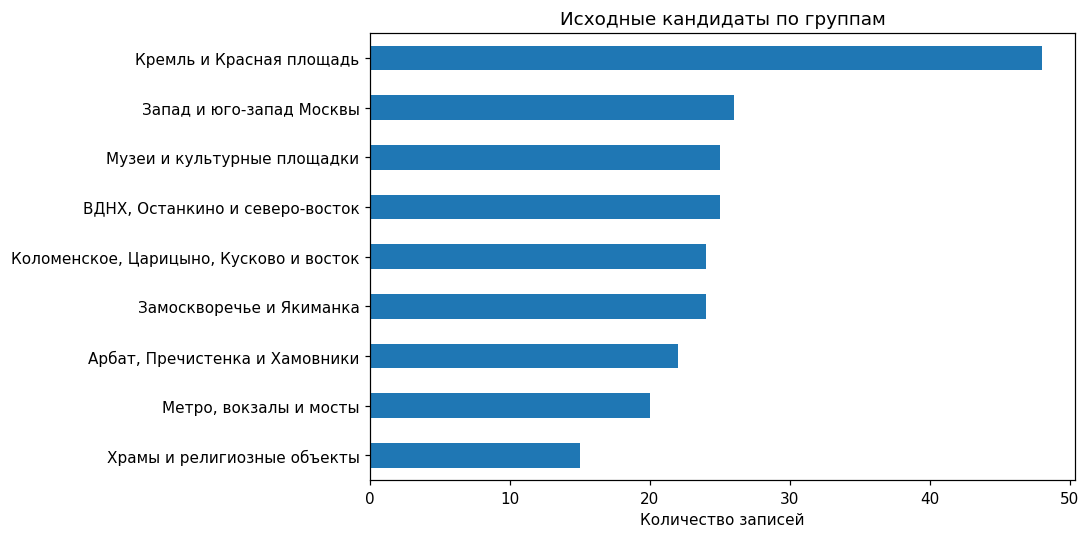

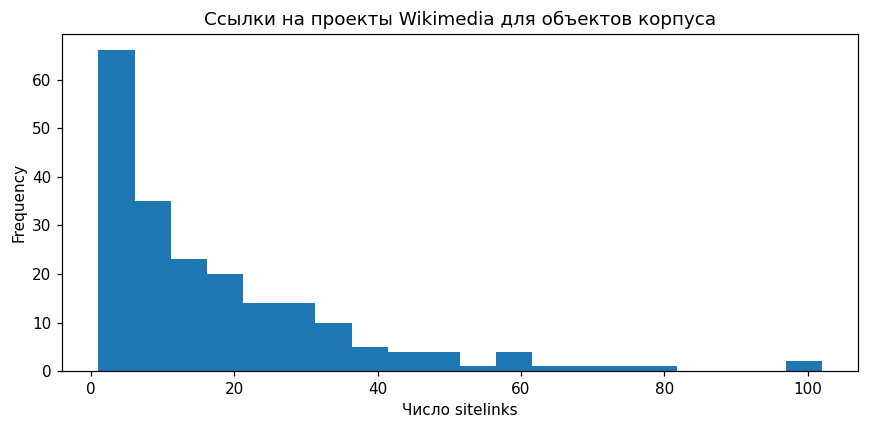

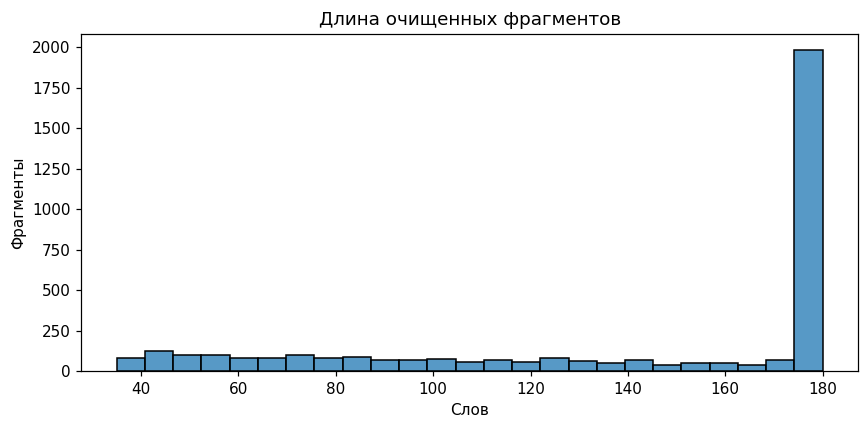

,fragments,pct,poi_count
история,333,8.93,110
архитектура,615,16.50,141
искусство,112,3.01,45
литература,91,2.44,42
музыка,138,3.70,61
театр и кино,179,4.80,42
наука и технологии,21,0.56,10
нумизматика,8,0.21,5
военная история,52,1.40,33
религия,610,16.37,78


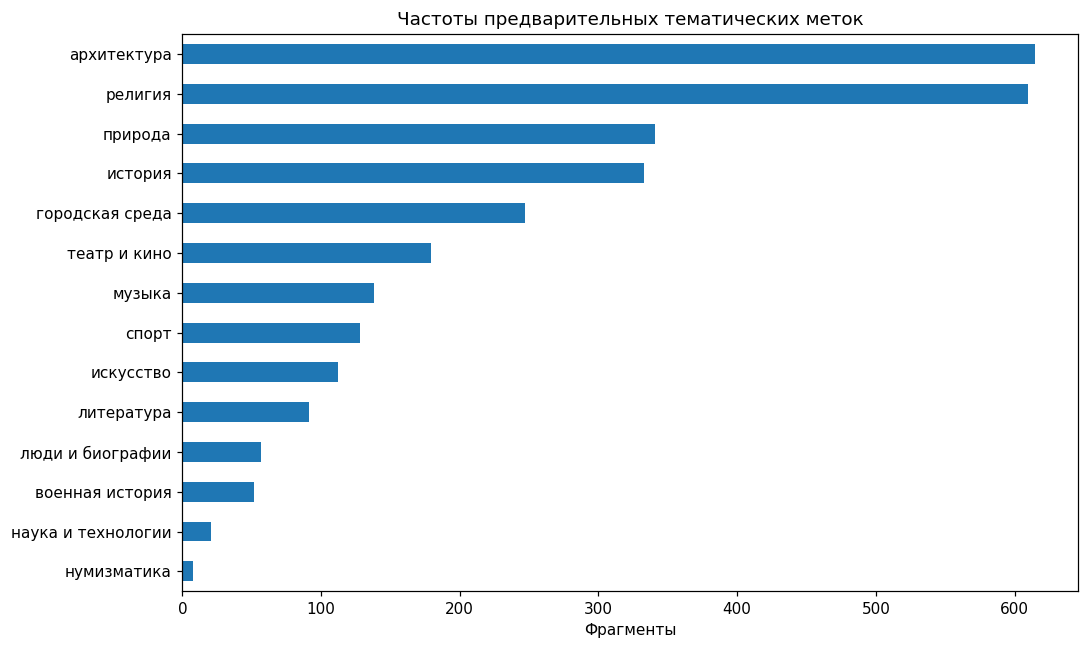

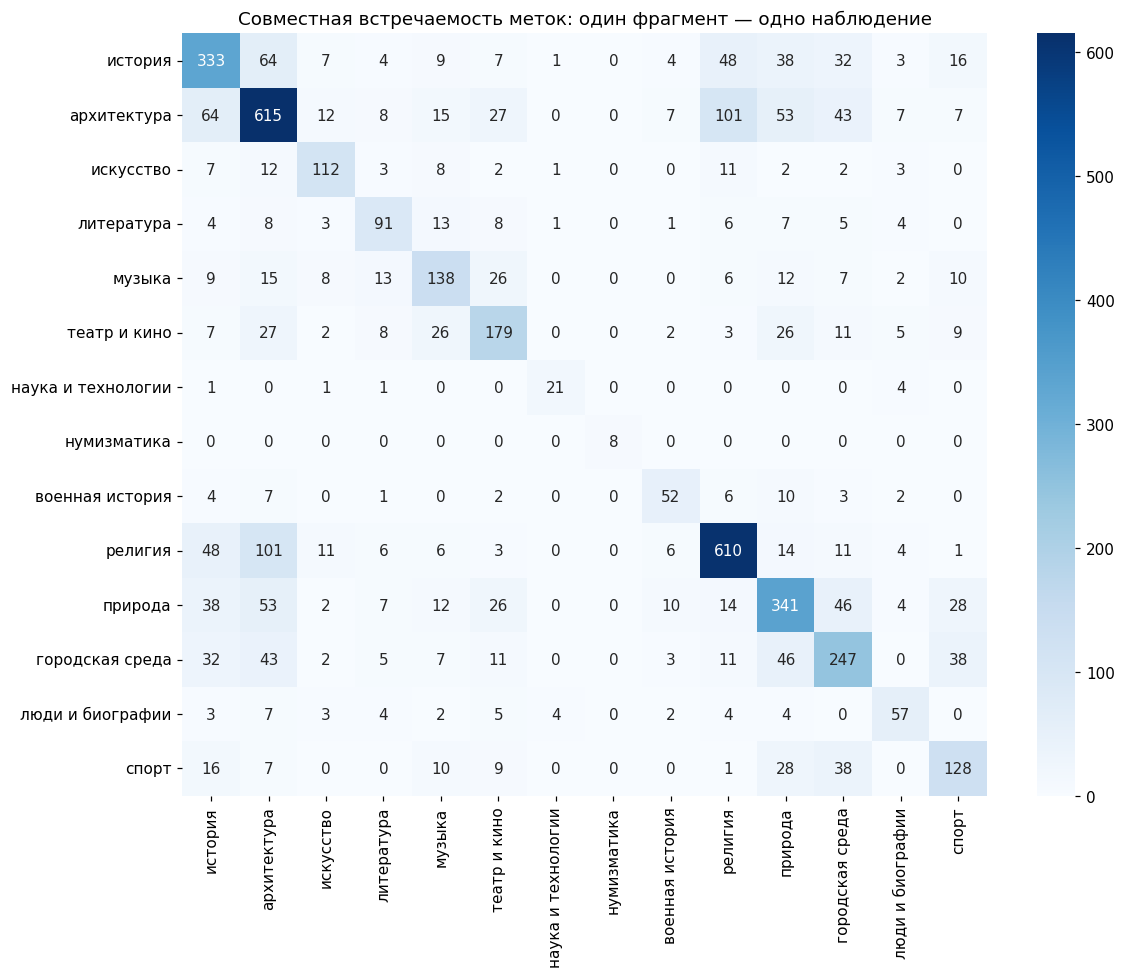

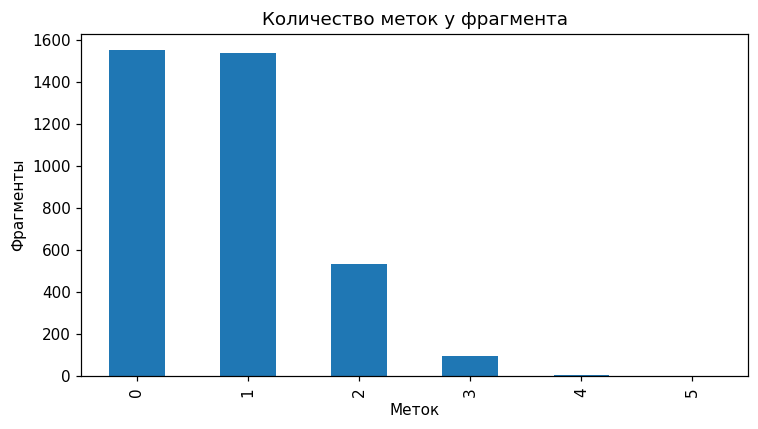

Фрагменты по длине


,word_count
count,3727.000000
mean,140.240140
std,50.207423
min,35.000000
25%,94.000000
50%,180.000000
75%,180.000000
max,180.000000


In [10]:
def show_plot(fig, filename):
    fig.tight_layout()
    fig.savefig(FIG_DIR/filename, bbox_inches='tight')
    plt.show()

fig, ax = plt.subplots(figsize=(10, 5))
pois_seed.area_group.value_counts().sort_values().plot.barh(ax=ax)
ax.set(title='Исходные кандидаты по группам', xlabel='Количество записей', ylabel='')
show_plot(fig, '02_seed_groups.png')

fig, ax = plt.subplots(figsize=(8, 4))
unique_pois.sitelinks.dropna().plot.hist(bins=20, ax=ax)
ax.set(title='Ссылки на проекты Wikimedia для объектов корпуса', xlabel='Число sitelinks')
show_plot(fig, '03_sitelinks.png')

fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(fragments.word_count, bins=25, ax=ax)
ax.set(title='Длина очищенных фрагментов', xlabel='Слов', ylabel='Фрагменты')
show_plot(fig, '04_fragment_length.png')

label_names = list(INTERESTS)
label_matrix = pd.DataFrame([[int(label in labs) for label in label_names] for labs in fragments.labels],
                            index=fragments.fragment_id, columns=label_names, dtype='int64')
counts = label_matrix.sum()
label_stats = pd.DataFrame({'fragments': counts,
    'pct': (100*counts/len(fragments)).round(2),
    'poi_count': [fragments[fragments.labels.map(lambda labs: label in labs)].qid.nunique() for label in label_names]})
label_stats.to_csv(OUT_DIR/'label_distribution.csv', encoding='utf-8-sig')
display(label_stats)
fig, ax = plt.subplots(figsize=(10, 6))
counts.sort_values().plot.barh(ax=ax)
ax.set(title='Частоты предварительных тематических меток', xlabel='Фрагменты', ylabel='')
show_plot(fig, '05_label_balance.png')

cooccurrence = label_matrix.T @ label_matrix
assert np.array_equal(np.diag(cooccurrence), counts.to_numpy())
cooccurrence.to_csv(OUT_DIR/'label_cooccurrence.csv', encoding='utf-8-sig')
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(cooccurrence, cmap='Blues', annot=True, fmt='d', ax=ax)
ax.set_title('Совместная встречаемость меток: один фрагмент — одно наблюдение')
show_plot(fig, '06_label_cooccurrence.png')

fig, ax = plt.subplots(figsize=(7, 4))
fragments.label_count.value_counts().sort_index().plot.bar(ax=ax)
ax.set(title='Количество меток у фрагмента', xlabel='Меток', ylabel='Фрагменты')
show_plot(fig, '07_labels_per_fragment.png')
print('Фрагменты по длине')
display(fragments.word_count.describe().to_frame())


**Промежуточный вывод**

- Архитектуры — 615 фрагментов, религии — 610, науки — 21, нумизматики — 8. Общая метрика может скрывать слабое качество редких тем
- Архитектура и религия встречаются вместе в 101 фрагменте. Темы не взаимоисключающие, задача должна оставаться многометочной
- Медиана и максимум длины равны 180 словам из-за размера окна. Это ограничение нарезки, а не естественная длина описаний


## 8. Проверка качества данных и выбросов

- Проверяем пропуски, пустые тексты, дубли, короткие фрагменты и долю кириллицы
- Выделяем длинные статьи по правилу 1,5 IQR и сохраняем выборку для проверки тематических меток


,count
исходные фрагменты,3728
пустые тексты до очистки,0
точные дубли до очистки,1
низкая доля кириллицы до очистки,0
удалено при очистке,1
фрагменты после очистки,3727
повторяющиеся ID после очистки,0
точные дубли после очистки,0
короткие фрагменты 35–39 слов,66
без тематической метки,1550


,missing_count
fragment_id,0
poi_id,0
qid,0
poi_title,0
source,0
source_url,0
section_title,0
text,0
word_count,0
cyrillic_share,0


Статей с большим объёмом по правилу 1.5 IQR: 21


,,words
qid,poi_title,
Q147994,Царицыно (дворцово-парковый ансамбль),16650
Q269373,Арбат,14042
Q191414,Мавзолей Ленина,11624
Q855493,Выставка достижений народного хозяйства,9362
Q1577987,Политехнический музей,8878
Q4165336,Дом Мельникова,7747
Q129846,Храм Василия Блаженного,7628
Q194474,Храм Христа Спасителя,7106
Q1048694,Российская государственная библиотека,6595


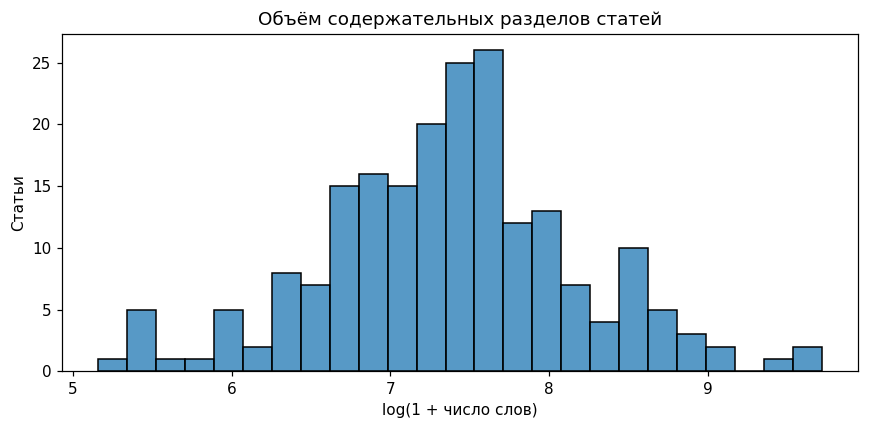

Примеров для проверки разметки: 22


,poi_title,section_title,label_list,text
3676,Рижский вокзал,Пригородное сообщение,,С Рижского вокзала отправляются пригородные эл...
3523,Новослободская (станция метро),Вестибюль,,"с полукруглым « приделом », в котором находитс..."
708,Памятник Минину и Пожарскому,Реставрации,,. Задний барельеф был отреставрирован и устано...
709,Памятник Минину и Пожарскому,Современное состояние,,В 2016 год памятник Минину и Пожарскому переда...
1297,Парк Горького (Москва),Детская железная дорога,,В 1932 году в Детском городке парка была откры...
711,Памятник Минину и Пожарскому,Современное состояние,,в него добавили около 500 кг медной массы. Фиг...
1443,Большая Ордынка,История,история;природа;городская среда,В сентябре 1612 года во время Московской битвы...
2500,Музей космонавтики (Москва),Современная деятельность,литература;наука и технологии;люди и биографии,— популяризатор космонавтики Виталий Егоров . ...


In [11]:
quality = pd.Series({
    'исходные фрагменты': len(raw_fragments),
    'пустые тексты до очистки': int(raw_fragments.text.isna().sum() + raw_fragments.text.str.strip().eq('').sum()),
    'точные дубли до очистки': int(raw_fragments.text.duplicated().sum()),
    'низкая доля кириллицы до очистки': int(raw_fragments.cyrillic_share.lt(0.25).sum()),
    'удалено при очистке': len(fragment_audit),
    'фрагменты после очистки': len(fragments),
    'повторяющиеся ID после очистки': int(fragments.fragment_id.duplicated().sum()),
    'точные дубли после очистки': int(fragments.text.duplicated().sum()),
    'короткие фрагменты 35–39 слов': int(fragments.word_count.lt(40).sum()),
    'без тематической метки': int(fragments.label_count.eq(0).sum()),
    'больше двух меток': int(fragments.label_count.gt(2).sum())
}, name='count')
quality.to_csv(OUT_DIR/'quality_summary.csv', encoding='utf-8-sig')
display(quality.to_frame())
display(fragments.isna().sum().to_frame('missing_count'))
article_words = sections.assign(words=sections.section_text.str.split().str.len()).groupby(['qid', 'poi_title']).words.sum()
q1, q3 = article_words.quantile([0.25, 0.75])
long_articles = article_words[article_words > q3 + 1.5*(q3-q1)].sort_values(ascending=False)
print('Статей с большим объёмом по правилу 1.5 IQR:', len(long_articles))
display(long_articles.head(10).to_frame('words'))
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(np.log1p(article_words), bins=25, ax=ax)
ax.set(title='Объём содержательных разделов статей', xlabel='log(1 + число слов)', ylabel='Статьи')
show_plot(fig, '08_article_length.png')

rare_labels = label_stats[label_stats.fragments.lt(100)].index.tolist()
review_parts = [fragments[fragments.label_count.eq(0)].sample(n=min(6, int(fragments.label_count.eq(0).sum())), random_state=SEED),
                fragments[fragments.label_count.gt(2)].sample(n=min(6, int(fragments.label_count.gt(2).sum())), random_state=SEED)]
for label in rare_labels:
    pool = fragments[fragments.labels.map(lambda labs: label in labs)]
    review_parts.append(pool.sample(n=min(2, len(pool)), random_state=SEED))
review_sample = pd.concat(review_parts).drop_duplicates('fragment_id')
review_sample['review_comment'] = ''
review_sample.to_csv(OUT_DIR/'annotation_review_sample.csv', index=False, encoding='utf-8-sig')
print('Примеров для проверки разметки:', len(review_sample))
display(review_sample[['poi_title', 'section_title', 'label_list', 'text']].head(8))


**Промежуточный вывод**

- Пустых текстов и фрагментов с низкой долей кириллицы нет. Эти проверки не подтверждают правильность фактов и тематических меток
- Остались 66 фрагментов по 35–39 слов. Их длина сама по себе не доказывает плохое качество, но начало и конец рассказа могут требовать контекста раздела
- 21 статья выделяется объёмом и даёт больше обучающих фрагментов. Длинные статьи не удаляем, но при расширении корпуса нужно следить за вкладом отдельных POI


## 9. Baseline: TF-IDF + Logistic Regression

- Делим данные по QID, чтобы фрагменты одного объекта не пересекались между train и test
- Обучаем TF-IDF и логистическую регрессию на фрагментах с метками, словарь строим только на train
- Считаем F1, смотрим число тестовых примеров и характерные слова для каждой темы


Train: 1610 фрагментов, 154 POI
Test: 567 фрагментов, 52 POI


,micro_f1,macro_f1,hamming_loss
TF-IDF + Logistic Regression,0.6305,0.3646,0.0608


,label,train_positive,test_positive
0,история,274,59
1,архитектура,472,143
2,искусство,96,16
3,литература,59,32
4,музыка,95,43
5,театр и кино,87,92
6,наука и технологии,21,0
7,нумизматика,6,2
8,военная история,43,9
9,религия,429,181


,precision,recall,f1-score,support
история,0.179,0.085,0.115,59.0
архитектура,0.699,0.650,0.674,143.0
искусство,0.625,0.625,0.625,16.0
литература,0.667,0.062,0.114,32.0
музыка,0.750,0.070,0.128,43.0
театр и кино,0.974,0.413,0.580,92.0
наука и технологии,0.000,0.000,0.000,0.0
нумизматика,0.000,0.000,0.000,2.0
военная история,0.000,0.000,0.000,9.0
религия,0.941,0.884,0.912,181.0


,label,top_terms
0,история,"вокзала, вокзал, была, года, году, проект, был..."
1,архитектура,"здание, строительство, здания, архитектуры, ар..."
2,искусство,"художников, коллекция, искусства, картина, муз..."
3,литература,"писатель, поэта, поэт, маяковского, музея, муз..."
4,музыка,"музыки, музыка, концерты, оперы, театра, консе..."
5,театр и кино,"театра, театр, кинотеатр, останкино, большого ..."
6,наука и технологии,"исследования, колокол, космоса, научно, област..."
7,нумизматика,"серии, монет, номиналом, марка, монета, копеек..."
8,военная история,"полка, война, войны, военной, великой отечеств..."
9,религия,"храма, монастыря, храм, собора, церковь, собор..."


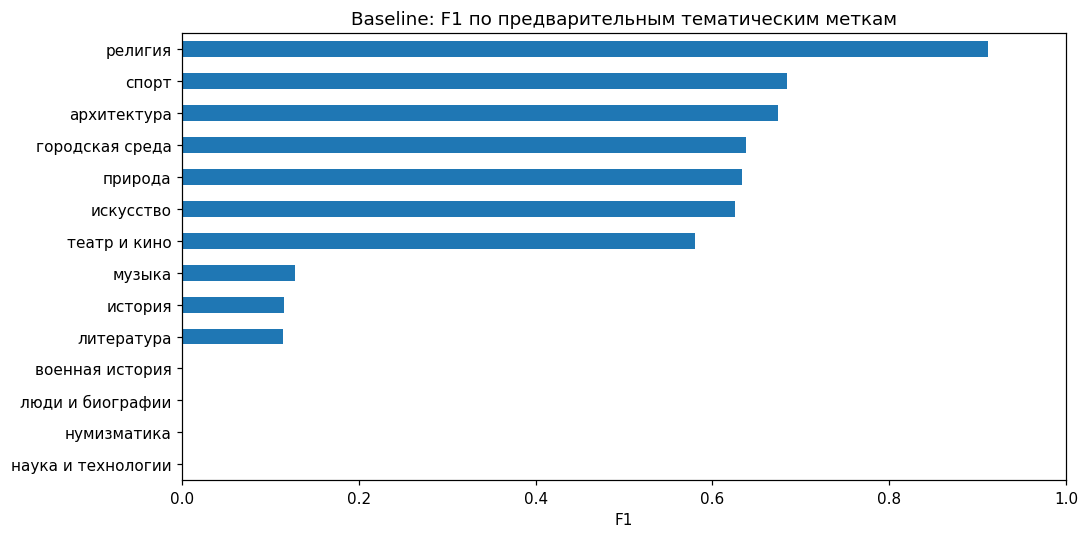

In [12]:
model_df = fragments[fragments.label_count.gt(0)].copy().reset_index(drop=True)
mlb_labels = list(INTERESTS)
Y = np.array([[int(label in labs) for label in mlb_labels] for labs in model_df.labels])
assert len(model_df) >= 30 and model_df.qid.nunique() >= 3, 'Мало данных для baseline'
tr, te = next(GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=SEED).split(model_df, Y, groups=model_df.qid))
assert set(model_df.qid.iloc[tr]).isdisjoint(model_df.qid.iloc[te])
assert set(model_df.text.iloc[tr]).isdisjoint(model_df.text.iloc[te])
supported = np.flatnonzero((Y[tr].sum(axis=0) > 0) & (Y[tr].sum(axis=0) < len(tr)))
assert len(supported) > 1, 'В train недостаточно классов'
support_table = pd.DataFrame({'label': mlb_labels, 'train_positive': Y[tr].sum(axis=0),
                              'test_positive': Y[te].sum(axis=0)})
support_table.to_csv(OUT_DIR/'split_label_support.csv', index=False, encoding='utf-8-sig')
model_df.assign(split=np.where(model_df.index.isin(tr), 'train', 'test')).to_csv(
    OUT_DIR/'model_split.csv', index=False, encoding='utf-8-sig')

def fit_baseline(train_texts, train_y):
    vectorizer = TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=40000,
                                sublinear_tf=True, max_df=0.98)
    xtrain = vectorizer.fit_transform(train_texts)
    xtest = vectorizer.transform(model_df.text.iloc[te])
    classifier = OneVsRestClassifier(LogisticRegression(max_iter=1000, class_weight='balanced',
                                                        solver='liblinear', random_state=SEED))
    classifier.fit(xtrain, train_y[:, supported])
    predicted = np.zeros((len(te), len(mlb_labels)), dtype=int)
    predicted[:, supported] = classifier.predict(xtest)
    return vectorizer, classifier, predicted

def score_predictions(predicted):
    return {'micro_f1': float(f1_score(Y[te], predicted, average='micro', zero_division=0)),
            'macro_f1': float(f1_score(Y[te], predicted, average='macro', zero_division=0)),
            'hamming_loss': float(hamming_loss(Y[te], predicted))}

vec, clf, pred = fit_baseline(model_df.text.iloc[tr], Y[tr])
baseline_metrics = score_predictions(pred)
print('Train:', len(tr), 'фрагментов,', model_df.qid.iloc[tr].nunique(), 'POI')
print('Test:', len(te), 'фрагментов,', model_df.qid.iloc[te].nunique(), 'POI')
display(pd.DataFrame([baseline_metrics], index=['TF-IDF + Logistic Regression']).round(4))
display(support_table)
report = pd.DataFrame(classification_report(Y[te], pred, target_names=mlb_labels,
                                            zero_division=0, output_dict=True)).T
report.to_csv(OUT_DIR/'baseline_classification_report.csv', encoding='utf-8-sig')
display(report.round(3))
terms = vec.get_feature_names_out()
features = pd.DataFrame([{'label': mlb_labels[i],
    'top_terms': ', '.join(terms[np.argsort(est.coef_[0])[-8:][::-1]])}
    for i, est in zip(supported, clf.estimators_)])
features.to_csv(OUT_DIR/'baseline_top_terms.csv', index=False, encoding='utf-8-sig')
display(features)
fig, ax = plt.subplots(figsize=(10, 5))
report.loc[mlb_labels, 'f1-score'].sort_values().plot.barh(ax=ax)
ax.set(title='Baseline: F1 по предварительным тематическим меткам', xlabel='F1', ylabel='', xlim=(0, 1))
show_plot(fig, '09_baseline_per_label.png')


**Промежуточный вывод**

- Micro-F1 — 0,630, macro-F1 — 0,365. Качество по темам неравномерно: F1 религии — 0,912, истории — 0,115
- В тесте нет науки и только два примера нумизматики. F1 науки включён в macro как ноль, хотя оценить её качество здесь нельзя. Для сравнения моделей нужен тест с покрытием всех тем
- Для религии модель использует ожидаемые слова «храм» и «монастырь», а среди признаков истории выделяются «вокзал» и «вокзала». Стоит проверить зависимость разметки от состава объектов
- Метрики получены только на фрагментах с автоматическими метками. Качество на неразмеченной части корпуса пока неизвестно


## 10. Проверка аугментаций

- Проверяем удаление части строчных слов, перестановку предложений и нормализацию типографики
- Преобразуем только train, исключаем совпадения с test и сравниваем модели на одном тесте
- Смотрим изменение метрик и примеры преобразованных текстов


,method,added_rows,micro_f1,macro_f1,hamming_loss,delta_micro_f1
0,Без аугментации,0,0.6305,0.3646,0.0608,0.0000
1,Удаление части строчных слов,1428,0.6245,0.3562,0.0606,-0.0059
2,Перестановка предложений,1568,0.6292,0.3608,0.0598,-0.0013
3,Нормализация типографики,1431,0.6313,0.3611,0.0596,0.0009


,method,before,after
0,Удаление части строчных слов,С началом в X веке славянской колонизации басс...,С началом в X славянской колонизации бассейнов...
1,Перестановка предложений,С началом в X веке славянской колонизации басс...,К докняжескому времени относятся и кремлёвские...
2,Нормализация типографики,С началом в X веке славянской колонизации басс...,С началом в X веке славянской колонизации басс...


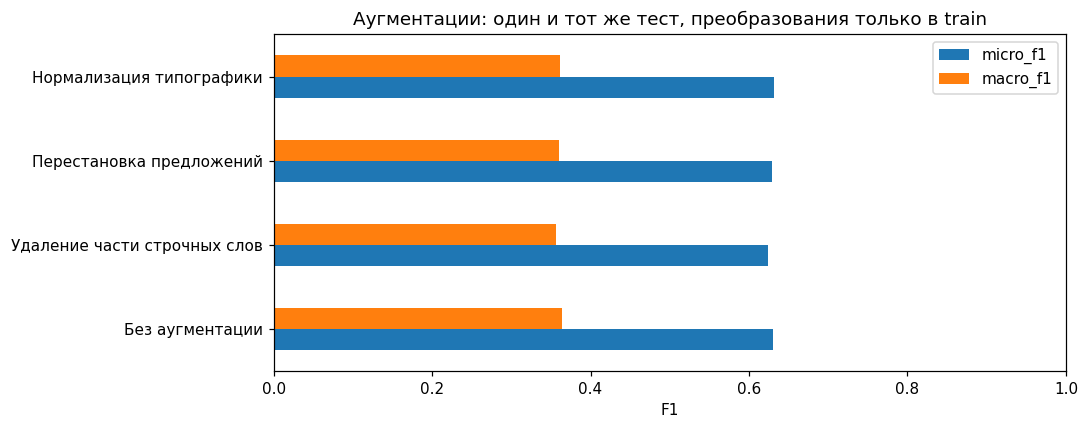

In [13]:
def word_dropout(text, rng, p=0.04):
    words = text.split()
    kept = [w for w in words if not (w.islower() and w.isalpha() and len(w) >= 4 and rng.random() < p)]
    return ' '.join(kept)

def shuffle_sentences(text, rng):
    parts = re.split(r'(?<=[.!?])\s+', text)
    rng.shuffle(parts)
    return ' '.join(parts)

def normalize_typography(text, rng):
    return re.sub(r'\s+', ' ', text.translate(str.maketrans({'«': '"', '»': '"', '—': '-', '–': '-', '\u00a0': ' '}))).strip()

methods = {'Удаление части строчных слов': word_dropout,
           'Перестановка предложений': shuffle_sentences,
           'Нормализация типографики': normalize_typography}
augmentation_results = [{'method': 'Без аугментации', 'added_rows': 0, **baseline_metrics}]
augmentation_examples = []
original_train = model_df.text.iloc[tr].tolist()
test_before = model_df.text.iloc[te].copy()
holdout_texts = set(test_before)
for method, transform in methods.items():
    rng = random.Random(SEED)
    extra_text, extra_y = [], []
    seen = set(original_train)
    for text, target in zip(original_train, Y[tr]):
        changed = transform(text, rng)
        if changed != text and changed not in seen and changed not in holdout_texts:
            extra_text.append(changed)
            extra_y.append(target)
            seen.add(changed)
            if not any(example['method'] == method for example in augmentation_examples):
                augmentation_examples.append({'method': method, 'before': text, 'after': changed})
    assert set(original_train + extra_text).isdisjoint(holdout_texts)
    if extra_text:
        train_y = np.vstack([Y[tr], np.array(extra_y)])
        _, _, method_pred = fit_baseline(original_train + extra_text, train_y)
        metrics = score_predictions(method_pred)
    else:
        metrics = baseline_metrics.copy()
    augmentation_results.append({'method': method, 'added_rows': len(extra_text), **metrics})
assert test_before.equals(model_df.text.iloc[te])
augmentation_results = pd.DataFrame(augmentation_results)
augmentation_results['delta_micro_f1'] = augmentation_results.micro_f1 - baseline_metrics['micro_f1']
augmentation_results.to_csv(OUT_DIR/'augmentation_comparison.csv', index=False, encoding='utf-8-sig')
pd.DataFrame(augmentation_examples).to_csv(OUT_DIR/'augmentation_examples.csv', index=False, encoding='utf-8-sig')
display(augmentation_results.round(4))
display(pd.DataFrame(augmentation_examples).assign(before=lambda d: d.before.str[:250], after=lambda d: d.after.str[:250]))
fig, ax = plt.subplots(figsize=(10, 4))
augmentation_results.set_index('method')[['micro_f1', 'macro_f1']].plot.barh(ax=ax)
ax.set(title='Аугментации: один и тот же тест, преобразования только в train', xlabel='F1', ylabel='', xlim=(0, 1))
show_plot(fig, '10_augmentation_comparison.png')


**Промежуточный вывод**

- Удаление слов снизило micro-F1 примерно на 0,006. В примере исчезло слово «веке», поэтому такой текст нельзя автоматически использовать в экскурсии
- Перестановка предложений дала около −0,001 к micro-F1, нормализация типографики — около +0,001, но снизила macro-F1
- На одном разбиении убедительного выигрыша нет. Оставляем baseline без аугментации, а исходные тексты для рассказов не меняем


## 11. Сохранение результатов

- Сохраняем корпус, метки, разделение train/test, таблицы качества, метрики и графики
- Собираем архив и записываем параметры снимка для повторного запуска


In [14]:
import shutil
from datetime import datetime, timezone
summary = {'analysis_at_utc': datetime.now(timezone.utc).isoformat(),
    'seed_rows': len(pois_seed), 'matched_rows': int(pois.qid.notna().sum()),
    'unique_pois': len(unique_pois), 'articles_downloaded': successful_articles,
    'sections': len(sections), 'raw_fragments': len(raw_fragments), 'clean_fragments': len(fragments),
    'labeled_fragments': int(fragments.label_count.gt(0).sum()),
    'unlabeled_fragments': int(fragments.label_count.eq(0).sum()),
    'baseline': baseline_metrics, 'text_parser_version': 2,
    'article_mapping': dict(zip(unique_pois.qid, unique_pois.article_title))}
(OUT_DIR/'run_summary.json').write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding='utf-8')
pois_seed.to_csv(OUT_DIR/'poi_candidates.csv', index=False, encoding='utf-8-sig')
fragments.to_csv(OUT_DIR/'fragments_weakly_labeled.csv', index=False, encoding='utf-8-sig')
zip_path = shutil.make_archive('/content/moscow_ai_guide_results', 'zip', OUT_DIR)
print('Графиков сохранено:', len(list(FIG_DIR.glob('*.png'))))
print('Архив:', zip_path)
print(json.dumps({k: v for k, v in summary.items() if k != 'article_mapping'}, ensure_ascii=False, indent=2))
files.download(zip_path)


Графиков сохранено: 10
Архив: /content/moscow_ai_guide_results.zip
{
  "analysis_at_utc": "2026-11-09T07:24:19.604968+00:00",
  "seed_rows": 229,
  "matched_rows": 226,
  "unique_pois": 206,
  "articles_downloaded": 206,
  "sections": 1978,
  "raw_fragments": 3728,
  "clean_fragments": 3727,
  "labeled_fragments": 2177,
  "unlabeled_fragments": 1550,
  "baseline": {
    "micro_f1": 0.630451415455241,
    "macro_f1": 0.3645675471401395,
    "hamming_loss": 0.06084656084656084
  },
  "text_parser_version": 2
}


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Выводы по EDA

- Собран корпус по 206 объектам: 1978 разделов и 3727 фрагментов с привязкой к источникам. Проверка статей обязательна: координаты ловят чужие города, но не все подмены объектов внутри Москвы
- Автоматические правила оставили без меток 41,6% фрагментов, включая содержательные исторические тексты. Основная следующая работа — проверка и улучшение разметки
- Архитектура и религия представлены намного лучше редких тем. Нужен добор примеров науки и нумизматики и тест, в котором присутствуют все темы
- Baseline дал micro-F1 0,630 и macro-F1 0,365 по слабым меткам. Это ориентир на размеченной части корпуса, качество на остальных текстах и качество экскурсии ещё не измерены
- Три аугментации не дали убедительного улучшения. Сохраняем простой baseline, сначала улучшаем данные и независимую оценку

Корпус подходит для следующего этапа — обучения классификатора тем и отбора фактов для рассказа LLM. Для выбора учебной нейросетевой модели сначала нужно проверить метки на сохранённой выборке и подготовить ручной тест
